In [1]:
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt

# Problem 1

In [2]:
# Defining the Denavit-Hartenberg transformation parameters
theta1, theta2, theta3, theta4 = sp.symbols("theta1 theta2 theta3 theta4", real=True)
d1, d2, d3, d4 = 50, 0, 0, 0
a1, a2, a3, a4 = 0, 93, 93, 50
alpha1, alpha2, alpha3, alpha4 = 90, 0, 0, 0


In [3]:
# Function to compute the Denavit-Hartenberg transformation matrix
def dh_transformation(theta, d, a, alpha):
    return sp.Matrix([
        [sp.cos(theta), -sp.sin(theta) * sp.cos(alpha), sp.sin(theta) * sp.sin(alpha), a * sp.cos(theta)],
        [sp.sin(theta), sp.cos(theta) * sp.cos(alpha), -sp.cos(theta) * sp.sin(alpha), a * sp.sin(theta)],
        [0, sp.sin(alpha), sp.cos(alpha), d],
        [0, 0, 0, 1]
    ])

# Compute the transformation matrices for each joint
T1 = dh_transformation(theta1, d1, a1, sp.rad(alpha1))
T2 = dh_transformation(theta2 + sp.pi/2, d2, a2, sp.rad(alpha2)) # Adding 90 degrees to theta2 for the correct orientation
T3 = dh_transformation(theta3, d3, a3, sp.rad(alpha3))
T4 = dh_transformation(theta4, d4, a4, sp.rad(alpha4))

# Computing T04 for the robot stylus:
T04 = T1 * T2 * T3 * T4
sp.simplify(T04)

Matrix([
[-sin(theta2 + theta3 + theta4)*cos(theta1), -cos(theta1)*cos(theta2 + theta3 + theta4),  sin(theta1), -(93*sin(theta2) + 93*sin(theta2 + theta3) + 50*sin(theta2 + theta3 + theta4))*cos(theta1)],
[-sin(theta1)*sin(theta2 + theta3 + theta4), -sin(theta1)*cos(theta2 + theta3 + theta4), -cos(theta1), -(93*sin(theta2) + 93*sin(theta2 + theta3) + 50*sin(theta2 + theta3 + theta4))*sin(theta1)],
[             cos(theta2 + theta3 + theta4),             -sin(theta2 + theta3 + theta4),            0,           93*cos(theta2) + 93*cos(theta2 + theta3) + 50*cos(theta2 + theta3 + theta4) + 50],
[                                         0,                                          0,            0,                                                                                          1]])

In [4]:
# T5 is just translation along the x-axis by -15 mm and along the y-axis by 45 mm.
T5 = sp.Matrix([
    [1, 0, 0, -15],
    [0, 1, 0, 45],
    [0, 0, 1, 0],
    [0, 0, 0, 1]
])
# getting the position T05 for the camera:
T05 = T04 * T5
sp.simplify(T05)

Matrix([
[-sin(theta2 + theta3 + theta4)*cos(theta1), -cos(theta1)*cos(theta2 + theta3 + theta4),  sin(theta1), -(93*sin(theta2) + 93*sin(theta2 + theta3) + 35*sin(theta2 + theta3 + theta4) + 45*cos(theta2 + theta3 + theta4))*cos(theta1)],
[-sin(theta1)*sin(theta2 + theta3 + theta4), -sin(theta1)*cos(theta2 + theta3 + theta4), -cos(theta1), -(93*sin(theta2) + 93*sin(theta2 + theta3) + 35*sin(theta2 + theta3 + theta4) + 45*cos(theta2 + theta3 + theta4))*sin(theta1)],
[             cos(theta2 + theta3 + theta4),             -sin(theta2 + theta3 + theta4),            0,          -45*sin(theta2 + theta3 + theta4) + 93*cos(theta2) + 93*cos(theta2 + theta3) + 35*cos(theta2 + theta3 + theta4) + 50],
[                                         0,                                          0,            0,                                                                                                                             1]])

# Problem 2

In [5]:
# Creating a function to compute the forward kinematics for given joint angles, returning the transformation matrix T04.
T04_func = sp.lambdify((theta1, theta2, theta3, theta4), T04, 'numpy')

def fk(q):
    return np.array(T04_func(*q), dtype=float)

print("T04 at q = 0 (upright pose):\n", fk([0, 0, 0, 0]).round(3))

T04 at q = 0 (upright pose):
 [[ -0.  -1.   0.  -0.]
 [  0.   0.  -1.   0.]
 [  1.  -0.   0. 286.]
 [  0.   0.   0.   1.]]


In [6]:
def Atan2(c, s):
    """Slide/Spong convention: Atan2(cos side, sin side). (numpy is arctan2(sin, cos))"""
    return np.arctan2(s, c)


def inverse_kinematics(o, r31, elbow_up=True):
    """
    o   = [o_x, o_y, o_z]  : stylus tip position o_4^0 [mm]
    r31 = last component of x_4^0 (= cos(theta2+theta3+theta4))
    returns [theta1, theta2, theta3, theta4] in rad
    """
    o_x, o_y, o_z = o

    # (slide 42): base angle
    th1 = Atan2(o_x, o_y)
    c1, s1 = np.cos(th1), np.sin(th1)

    # (slide 39): wrist centre o_c = o - a4 * R * [1,0,0]^T
    # s234 = -sqrt(1 - r31^2)  (stylus pointing outward) -> r11 = c1*sqrt(..), r21 = s1*sqrt(..)
    w = np.sqrt(1 - r31**2)
    r11, r21 = c1 * w, s1 * w
    x_c = o_x - a4 * r11
    y_c = o_y - a4 * r21
    z_c = o_z - a4 * r31

    # (slide 43): law of cosines for theta3
    r = np.sqrt(x_c**2 + y_c**2)
    s = z_c - d1
    c3 = (r**2 + s**2 - a2**2 - a3**2) / (2 * a2 * a3)
    if abs(c3) > 1:
        raise ValueError("Point is out of reach")
    s3 = -np.sqrt(1 - c3**2) if elbow_up else np.sqrt(1 - c3**2)
    th3 = Atan2(c3, s3)

    # (slide 43, adapted to the +90 offset): theta2 measured from vertical
    th2 = Atan2(s, -r) - Atan2(a2 + a3 * c3, a3 * s3)

    # (slide 44): orientation -> theta2 + theta3 + theta4 = Atan2(r31, -w)
    th4 = Atan2(r31, -w) - th2 - th3

    return np.array([th1, th2, th3, th4])


# Testing the inverse kinematics function with a target position and orientation
o_target = np.array([150, 32, 120])
r31_target = 0.0                         # stylus horizontal

q = inverse_kinematics(o_target, r31_target)
print("q [rad] =", q.round(4))
print("q [deg] =", np.degrees(q).round(2))

T = fk(q)
print("FK check -> o_4 =", T[:3, 3].round(6), " r31 =", round(T[2, 0], 6))


q [rad] = [ 0.2102 -0.1406 -1.6699  0.2397]
q [deg] = [ 12.04  -8.06 -95.68  13.74]
FK check -> o_4 = [150.  32. 120.]  r31 = 0.0


# Problem 3

In [7]:
R = 32 #mm
p_c = np.array([150, 0, 120]) #mm
phis = np.linspace(0, 2*np.pi, 37)
x4z = 0

# Finding a sequence of 37 robot configurations:
Q = np.array([inverse_kinematics(p_c + R*np.array([0, np.cos(phi), np.sin(phi)]), x4z) for phi in phis])

print("-" * 60)
for j in range(0, 37, 3):
    print(f"| j={j:2d}  | phi={np.degrees(phis[j]):5.0f} deg   | q [deg] = {np.degrees(Q[j]).round(2)} |")
print("-" * 60)

------------------------------------------------------------
| j= 0  | phi=    0 deg   | q [deg] = [ 12.04  -8.06 -95.68  13.74] |
| j= 3  | phi=   30 deg   | q [deg] = [ 10.47  -6.03 -87.97   4.  ] |
| j= 6  | phi=   60 deg   | q [deg] = [  6.09  -4.93 -81.96  -3.12] |
| j= 9  | phi=   90 deg   | q [deg] = [  0.    -4.6  -79.66  -5.74] |
| j=12  | phi=  120 deg   | q [deg] = [ -6.09  -4.93 -81.96  -3.12] |
| j=15  | phi=  150 deg   | q [deg] = [-10.47  -6.03 -87.97   4.  ] |
| j=18  | phi=  180 deg   | q [deg] = [-12.04  -8.06 -95.68  13.74] |
| j=21  | phi=  210 deg   | q [deg] = [ -10.47  -10.77 -102.92   23.69] |
| j=24  | phi=  240 deg   | q [deg] = [  -6.09  -13.26 -107.98   31.24] |
| j=27  | phi=  270 deg   | q [deg] = [  -0.    -14.3  -109.78   34.08] |
| j=30  | phi=  300 deg   | q [deg] = [   6.09  -13.26 -107.98   31.24] |
| j=33  | phi=  330 deg   | q [deg] = [  10.47  -10.77 -102.92   23.69] |
| j=36  | phi=  360 deg   | q [deg] = [ 12.04  -8.06 -95.68  13.74] |
---------

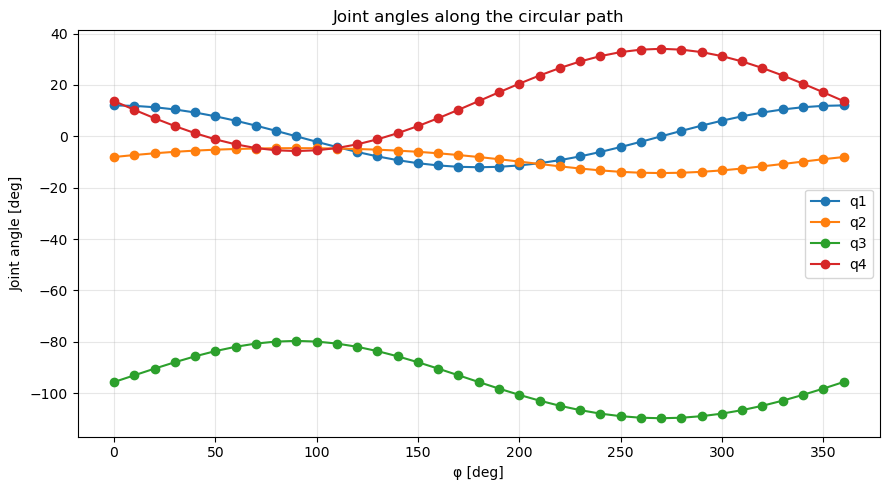

In [8]:
plt.figure(figsize=(9, 5))

for i in range(4):
    plt.plot(np.degrees(phis), np.degrees(Q[:, i]), marker="o", label=f"q{i+1}")

plt.xlabel("φ [deg]")
plt.ylabel("Joint angle [deg]")
plt.title("Joint angles along the circular path")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Problem 4

In [9]:
# The Jacobian of the manipulator for the robot end-effector and the Jacobian for the robot camera (as a function of the joint configuration q).

# Transfomation matrices up to the end-effector (stylus) and the camera:
T01 = T1
T02 = T1 * T2
T03 = T1 * T2 * T3
# T04 and T05 are already defined above

# Column i:  J_i = [ z_{i-1} x (o_n - o_{i-1}) ;  z_{i-1} ]: 
def geometric_jacobian(T0n):
    frames = [sp.eye(4), T01, T02, T03]          # T_0^0, T_1^0, T_2^0, T_3^0
    o_n = T0n[:3, 3]

    cols = []
    for Ti in frames:
        z = Ti[:3, 2]                            # z_{i-1}
        o_i = Ti[:3, 3]                          # o_{i-1}
        Jv = z.cross(o_n - o_i)                  # linear velocity part
        Jw = z                                    # angular velocity part
        cols.append(sp.Matrix.vstack(Jv, Jw))    # column i of the Jacobian
    return sp.simplify(sp.Matrix.hstack(*cols))

J4 = geometric_jacobian(T04)    # stylus
J5 = geometric_jacobian(T05)    # camera
J4


Matrix([
[ (93*sin(theta2) + 93*sin(theta2 + theta3) + 50*sin(theta2 + theta3 + theta4))*sin(theta1), -(93*cos(theta2) + 93*cos(theta2 + theta3) + 50*cos(theta2 + theta3 + theta4))*cos(theta1), -(93*cos(theta2 + theta3) + 50*cos(theta2 + theta3 + theta4))*cos(theta1), -50*cos(theta1)*cos(theta2 + theta3 + theta4)],
[-(93*sin(theta2) + 93*sin(theta2 + theta3) + 50*sin(theta2 + theta3 + theta4))*cos(theta1), -(93*cos(theta2) + 93*cos(theta2 + theta3) + 50*cos(theta2 + theta3 + theta4))*sin(theta1), -(93*cos(theta2 + theta3) + 50*cos(theta2 + theta3 + theta4))*sin(theta1), -50*sin(theta1)*cos(theta2 + theta3 + theta4)],
[                                                                                         0,               -93*sin(theta2) - 93*sin(theta2 + theta3) - 50*sin(theta2 + theta3 + theta4),               -93*sin(theta2 + theta3) - 50*sin(theta2 + theta3 + theta4),             -50*sin(theta2 + theta3 + theta4)],
[                                                                  

In [10]:
J5

Matrix([
[ (93*sin(theta2) + 93*sin(theta2 + theta3) + 35*sin(theta2 + theta3 + theta4) + 45*cos(theta2 + theta3 + theta4))*sin(theta1), (45*sin(theta2 + theta3 + theta4) - 93*cos(theta2) - 93*cos(theta2 + theta3) - 35*cos(theta2 + theta3 + theta4))*cos(theta1), (45*sin(theta2 + theta3 + theta4) - 93*cos(theta2 + theta3) - 35*cos(theta2 + theta3 + theta4))*cos(theta1), 5*(9*sin(theta2 + theta3 + theta4) - 7*cos(theta2 + theta3 + theta4))*cos(theta1)],
[-(93*sin(theta2) + 93*sin(theta2 + theta3) + 35*sin(theta2 + theta3 + theta4) + 45*cos(theta2 + theta3 + theta4))*cos(theta1), (45*sin(theta2 + theta3 + theta4) - 93*cos(theta2) - 93*cos(theta2 + theta3) - 35*cos(theta2 + theta3 + theta4))*sin(theta1), (45*sin(theta2 + theta3 + theta4) - 93*cos(theta2 + theta3) - 35*cos(theta2 + theta3 + theta4))*sin(theta1), 5*(9*sin(theta2 + theta3 + theta4) - 7*cos(theta2 + theta3 + theta4))*sin(theta1)],
[                                                                                                

In [11]:
# numeric functions for the Jacobians and the position of the end-effector and camera:

J4_func = sp.lambdify((theta1, theta2, theta3, theta4), J4, 'numpy')
J5_func = sp.lambdify((theta1, theta2, theta3, theta4), J5, 'numpy')
o5_func = sp.lambdify((theta1, theta2, theta3, theta4), T05[:3, 3], 'numpy')

def J_stylus(q): return np.array(J4_func(*q), dtype=float)
def J_camera(q): return np.array(J5_func(*q), dtype=float)

#testing the Jacobians against a numerical derivative of the forward kinematics

#def numerical_Jv(pos_func, q, h=1e-6):
#    q = np.asarray(q, float)
#    return np.column_stack([(np.array(pos_func(*(q + h*e)), float).ravel() 
#                             - np.array(pos_func(*(q - h*e)), float).ravel()) 
#                             / (2*h) for e in np.eye(4)])

#q_test = Q[5]
#print("stylus: max |Jv - dFK/dq| =", np.abs(J_stylus(q_test)[:3] - numerical_Jv(lambda *q: fk(q)[:3, 3], q_test)).max())
#print("camera: max |Jv - dFK/dq| =", np.abs(J_camera(q_test)[:3] - numerical_Jv(o5_func, q_test)).max())


Numerical results at φ = 0, π/2, π, 3π/2 (j = 0, 9, 18, 27):

In [12]:
# 0 = 0, 9 = pi/2, 18 = pi, 27 = 3pi/2
for j, name in zip([0, 9, 18, 27], ["0", "pi/2", "pi", "3pi/2"]):
    print(f"===== phi = {name}   q = {np.degrees(Q[j]).round(2)} deg")
    print("J_stylus =\n", J_stylus(Q[j]))
    print("J_camera =\n", J_camera(Q[j]), "\n")

===== phi = 0   q = [ 12.04  -8.06 -95.68  13.74] deg
J_stylus =
 [[-3.20000000e+01 -6.84594985e+01  2.15960112e+01 -2.99423949e-15]
 [ 1.50000000e+02 -1.46046930e+01  4.60714905e+00 -6.38771092e-16]
 [ 0.00000000e+00  1.53375357e+02  1.40340392e+02  5.00000000e+01]
 [ 0.00000000e+00  2.08638472e-01  2.08638472e-01  2.08638472e-01]
 [ 0.00000000e+00 -9.77992836e-01 -9.77992836e-01 -9.77992836e-01]
 [ 1.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00]]
J_camera =
 [[ -28.87042292 -112.46917619  -22.41366647  -44.00967764]
 [ 135.33010745  -23.99342425   -4.78158218   -9.38873123]
 [   0.          138.37535656  125.34039229   35.        ]
 [   0.            0.20863847    0.20863847    0.20863847]
 [   0.           -0.97799284   -0.97799284   -0.97799284]
 [   1.            0.            0.            0.        ]] 

===== phi = pi/2   q = [  0.    -4.6  -79.66  -5.74] deg
J_stylus =
 [[-1.95943488e-15 -1.02000000e+02 -9.30018309e+00 -3.06161700e-15]
 [ 1.50000000e+02 -1.33241

# Problem 5

In [13]:
# configuration at φ = π/2
R_c, p_c = 32.0, np.array([150.0, 0.0, 120.0]) # from problem 3
phi = np.pi/2
o = p_c + R_c * np.array([0, np.cos(phi), np.sin(phi)])
q = inverse_kinematics(o, 0.0)
print("o_4 =", o, "mm,   q =", np.degrees(q).round(2), "deg")

o_4 = [1.50000000e+02 1.95943488e-15 1.52000000e+02] mm,   q = [  0.    -4.6  -79.66  -5.74] deg


In [14]:
# build the 4×4 system
def skew(w): #S(w)
    return np.array([[0, -w[2], w[1]],
                     [w[2], 0, -w[0]],
                     [-w[1], w[0], 0]])

J = J_stylus(q)            # 6x4 geometric Jacobian
Jv, Jw = J[:3], J[3:]      # linear and angular parts
x4 = fk(q)[:3, 0]          # x_4^0 = first column of T_4^0

# Annex A: x4dot = w x x4 = -S(x4) w = -S(x4) Jw qdot   -> take the z-row
row_x4z = (-skew(x4) @ Jw)[2]
print("row for x4dot_z =", row_x4z.round(4))      # should be proportional to [0, 1, 1, 1]

A = np.vstack([Jv, row_x4z])                    # 4x4
xi = np.array([0, -3, 0, 0, 0])                 # [v_x, v_y, v_z, w_x, w_y]
print("A =\n", A.round(3))

row for x4dot_z = [0. 1. 1. 1.]
A =
 [[  -0.    -102.      -9.3     -0.   ]
 [ 150.      -0.      -0.      -0.   ]
 [   0.     150.     142.534   50.   ]
 [   0.       1.       1.       1.   ]]


In [15]:
qdot = np.linalg.pinv(J_stylus(q)[:5]) @ xi    
print("qdot =", qdot.round(6), "rad/s")

qdot = [-0.02  0.    0.    0.  ] rad/s


In [16]:
# Checking the solution:
v4 = Jv @ qdot
w4 = Jw @ qdot
x4dot = skew(w4) @ x4
print("v_4    =", v4.round(6), "mm/s   (should be [0, -3, 0])")
print("x4dot  =", x4dot.round(6), "      (last component should be 0)")
print("sanity: -3 / 150 =", -3/150, "rad/s")

v_4    = [ 0. -3.  0.] mm/s   (should be [0, -3, 0])
x4dot  = [ 0.   -0.02  0.  ]       (last component should be 0)
sanity: -3 / 150 = -0.02 rad/s


# Problem 6

In [17]:
R_c, p_c = 32.0, np.array([150.0, 0.0, 120.0])
def circle(phi):
    return p_c + R_c * np.array([0, np.cos(phi), np.sin(phi)])

knot_phis = [0, np.pi/2, np.pi, 3*np.pi/2, 2*np.pi]        # = phi_0, phi_9, phi_18, phi_27, phi_36
Q_knots = np.array([inverse_kinematics(circle(f), 0.0) for f in knot_phis])

# Given tip velocities at the knots [mm/s]
V_knots = np.array([[0,   0,   0],
                    [0, -27,   0],
                    [0,   0, -27],
                    [0,  27,   0],
                    [0,   0,   0]])

def task_matrix(q):
    J = J_stylus(q)
    x4 = fk(q)[:3, 0]
    row_x4z = (-skew(x4) @ J[3:])[2]          # x4dot_z = 0  -> stylus stays horizontal
    return np.vstack([J[:3], row_x4z])

def joint_velocity(q, v):
    return np.linalg.solve(task_matrix(q), np.r_[v, 0])

Qd_knots = np.array([joint_velocity(q, v) for q, v in zip(Q_knots, V_knots)])
Qdd_knots = np.zeros_like(Q_knots)                         # Hint 2: zero acceleration at knots

print("knot    q [rad]                              qdot [rad/s]")
for k, name in enumerate(["q(0) ", "q(9) ", "q(18)", "q(27)", "q(36)"]):
    print(name, Q_knots[k].round(4), Qd_knots[k].round(4))

knot    q [rad]                              qdot [rad/s]
q(0)  [ 0.2102 -0.1406 -1.6699  0.2397] [0. 0. 0. 0.]
q(9)  [ 0.     -0.0804 -1.3903 -0.1002] [-0.18  0.   -0.    0.  ]
q(18) [-0.2102 -0.1406 -1.6699  0.2397] [ 0.     -0.0693 -0.2196  0.2889]
q(27) [-0.     -0.2496 -1.916   0.5949] [ 0.18  0.   -0.    0.  ]
q(36) [ 0.2102 -0.1406 -1.6699  0.2397] [0. 0. 0. 0.]


In [18]:
def quintic_coeffs(q0, qf, v0, vf, a0, af, T):
    """returns [c0, c1, c2, c3, c4, c5] with q(t) = c0 + c1 t + ... + c5 t^5"""
    M = np.array([[1, 0, 0,    0,      0,       0],
                  [0, 1, 0,    0,      0,       0],
                  [0, 0, 2,    0,      0,       0],
                  [1, T, T**2, T**3,   T**4,    T**5],
                  [0, 1, 2*T,  3*T**2, 4*T**3,  5*T**4],
                  [0, 0, 2,    6*T,    12*T**2, 20*T**3]])
    return np.linalg.solve(M, [q0, v0, a0, qf, vf, af])

T_seg = 2.0
coeffs = np.zeros((4, 4, 6))       # [segment, joint, power]
for seg in range(4):
    for i in range(4):
        coeffs[seg, i] = quintic_coeffs(Q_knots[seg, i], Q_knots[seg+1, i],
                                        Qd_knots[seg, i], Qd_knots[seg+1, i],
                                        Qdd_knots[seg, i], Qdd_knots[seg+1, i], T_seg)

In [19]:
np.set_printoptions(precision=6, suppress=True)
for seg, L in enumerate("ABCD"):
    print(f"\nSegment {L}:  columns = {L}i5, {L}i4, {L}i3, {L}i2, {L}i1, {L}i0")
    for i in range(4):
        print(f"  q{i+1}:", coeffs[seg, i, ::-1])


Segment A:  columns = Ai5, Ai4, Ai3, Ai2, Ai1, Ai0
  q1: [-0.005659  0.039546 -0.082728  0.        0.        0.210183]
  q2: [ 0.011298 -0.05649   0.07532   0.       -0.       -0.140624]
  q3: [ 0.052433 -0.262166  0.349555  0.        0.       -1.669903]
  q4: [-0.063731  0.318656 -0.424875  0.       -0.        0.23973 ]

Segment B:  columns = Bi5, Bi4, Bi3, Bi2, Bi1, Bi0
  q1: [-0.005659  0.017046  0.007272  0.       -0.18      0.      ]
  q2: [ 0.001691 -0.004125 -0.006046  0.        0.       -0.080368]
  q3: [-0.011258  0.070016 -0.129955  0.        0.       -1.390259]
  q4: [ 0.009567 -0.065891  0.136     0.       -0.       -0.100169]

Segment C:  columns = Ci5, Ci4, Ci3, Ci2, Ci1, Ci0
  q1: [ 0.005659 -0.039546  0.082728  0.       -0.       -0.210183]
  q2: [-0.00745   0.032921 -0.032349  0.       -0.069274 -0.140624]
  q3: [-0.004975  0.011149  0.021735  0.       -0.2196   -1.669903]
  q4: [ 0.012425 -0.044069  0.010614  0.        0.288874  0.23973 ]

Segment D:  columns = Di5, 

In [20]:
def trajectory(t):
    seg = min(int(t // T_seg), 3)
    tau = t - seg * T_seg
    c = coeffs[seg]
    q   = sum(c[:, k] * tau**k for k in range(6))
    qd  = sum(k * c[:, k] * tau**(k-1) for k in range(1, 6))
    qdd = sum(k * (k-1) * c[:, k] * tau**(k-2) for k in range(2, 6))
    return q, qd, qdd

t = np.linspace(0, 8, 801)
q_t, qd_t, qdd_t = map(np.array, zip(*[trajectory(ti) for ti in t]))

for k, tk in enumerate([0, 2, 4, 6, 8]):
    qk, qdk, qddk = trajectory(min(tk, 8 - 1e-12))
    print(f"t={tk}s  |q - q_knot| = {np.abs(qk - Q_knots[k]).max():.1e}   "
          f"v = {(J_stylus(qk)[:3] @ qdk).round(3)} mm/s   |qdd| = {np.abs(qddk).max():.1e}")

t=0s  |q - q_knot| = 0.0e+00   v = [ 0.  0. -0.] mm/s   |qdd| = 0.0e+00
t=2s  |q - q_knot| = 0.0e+00   v = [ -0. -27.   0.] mm/s   |qdd| = 0.0e+00
t=4s  |q - q_knot| = 0.0e+00   v = [ -0.  -0. -27.] mm/s   |qdd| = 0.0e+00
t=6s  |q - q_knot| = 0.0e+00   v = [-0. 27. -0.] mm/s   |qdd| = 0.0e+00
t=8s  |q - q_knot| = 2.2e-16   v = [-0. -0. -0.] mm/s   |qdd| = 2.7e-12


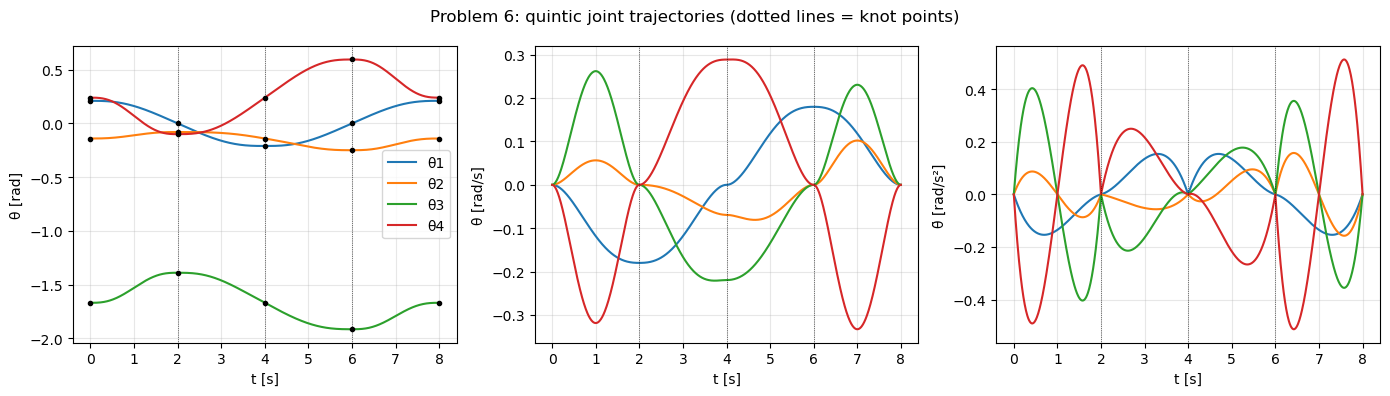

In [21]:
fig, axs = plt.subplots(1, 3, figsize=(14, 4))
for i in range(4):
    axs[0].plot(t, q_t[:, i], label=f"θ{i+1}")
    axs[1].plot(t, qd_t[:, i])
    axs[2].plot(t, qdd_t[:, i])
for ax, lab in zip(axs, ["θ [rad]", "θ̇ [rad/s]", "θ̈ [rad/s²]"]):
    ax.set_xlabel("t [s]"); ax.set_ylabel(lab); ax.grid(alpha=0.3)
    for tk in [2, 4, 6]: ax.axvline(tk, color="k", lw=0.5, ls=":")
axs[0].plot([0, 2, 4, 6, 8], Q_knots, "ko", ms=3)
axs[0].legend()
fig.suptitle("Problem 6: quintic joint trajectories (dotted lines = knot points)")
plt.tight_layout(); plt.show()

# Problem 7

In [22]:
# actual path and error

P_actual = np.array([fk(q)[:3, 3] for q in q_t])            # FK at every time sample

def circle_error(P):
    """distance from each point to the desired circle [mm]"""
    rho = np.sqrt(P[:, 1]**2 + (P[:, 2] - p_c[2])**2)       # distance from the centre in the y-z plane
    return np.sqrt((P[:, 0] - p_c[0])**2 + (rho - R_c)**2)

err_A = circle_error(P_actual)
P_circle = np.array([circle(f) for f in np.linspace(0, 2*np.pi, 400)])
P_knots = np.array([circle(f) for f in knot_phis])

print(f"Problem 6 trajectory: max error = {err_A.max():.2f} mm,  RMS = {np.sqrt(np.mean(err_A**2)):.2f} mm")

Problem 6 trajectory: max error = 2.91 mm,  RMS = 1.58 mm


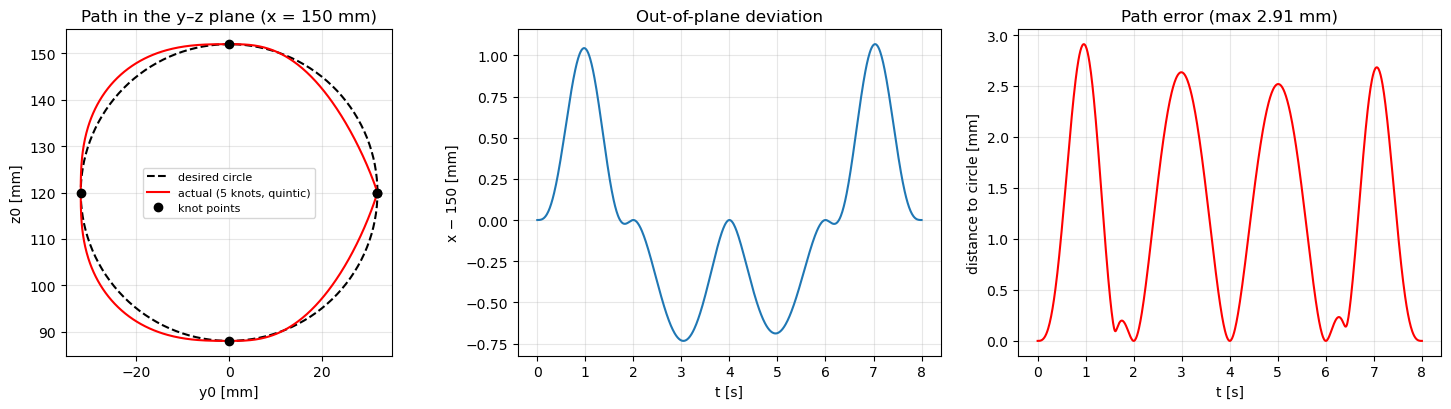

In [23]:
#plot actual vs desired path

fig, axs = plt.subplots(1, 3, figsize=(15, 4.2))
axs[0].plot(P_circle[:, 1], P_circle[:, 2], "k--", label="desired circle")
axs[0].plot(P_actual[:, 1], P_actual[:, 2], "r", label="actual (5 knots, quintic)")
axs[0].plot(P_knots[:, 1], P_knots[:, 2], "ko", label="knot points")
axs[0].set_aspect("equal"); axs[0].set_xlabel("y0 [mm]"); axs[0].set_ylabel("z0 [mm]")
axs[0].set_title("Path in the y–z plane (x = 150 mm)"); axs[0].legend(fontsize=8)

axs[1].plot(t, P_actual[:, 0] - 150)
axs[1].set_xlabel("t [s]"); axs[1].set_ylabel("x − 150 [mm]"); axs[1].set_title("Out-of-plane deviation")

axs[2].plot(t, err_A, "r")
axs[2].set_xlabel("t [s]"); axs[2].set_ylabel("distance to circle [mm]")
axs[2].set_title(f"Path error (max {err_A.max():.2f} mm)")
for ax in axs: ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

In [24]:
# improvement 1, more knot points

def more_knots(N, T_total=8.0):
    phis = np.linspace(0, 2*np.pi, N)                     # N equally spaced knots on the circle
    dt = T_total / (N - 1)                                # time per segment
    speed = R_c * (2*np.pi / T_total)                     # tip speed at interior knots (circumference / 8 s)

    Q_k = np.array([inverse_kinematics(circle(f), 0.0) for f in phis])
    Qd_k = np.zeros_like(Q_k)                             # start and end at rest
    for k in range(1, N - 1):
        v = speed * np.array([0, -np.sin(phis[k]), np.cos(phis[k])])   # tangent to the circle
        Qd_k[k] = joint_velocity(Q_k[k], v)               # Hint 1 (same as Problem 6)
    Qdd_k = np.zeros_like(Q_k)                            # Hint 2: zero acceleration at knots

    C = np.array([[quintic_coeffs(Q_k[s, i], Q_k[s+1, i], Qd_k[s, i], Qd_k[s+1, i],
                                  Qdd_k[s, i], Qdd_k[s+1, i], dt) for i in range(4)]
                  for s in range(N - 1)])
    def traj(tt):
        s = min(int(tt // dt), N - 2)
        tau = tt - s * dt
        return sum(C[s][:, k] * tau**k for k in range(6))
    return np.array([traj(ti) for ti in t])               # joint angles at every time sample

In [25]:
# improvement 2, interpolate in Cartesian (task) space

# Plan the circle angle phi(t) with a quintic from 0 to 2*pi in 8 s (start/end at rest, Lecture 6),
# then compute the joint angles with the IK at every time sample.
c_phi = quintic_coeffs(0, 2*np.pi, 0, 0, 0, 0, 8.0)
phi_t = lambda tt: sum(c_phi[k] * tt**k for k in range(6))

q_task = np.array([inverse_kinematics(circle(phi_t(ti)), 0.0) for ti in t])

method                        max error [mm]   RMS [mm]
Problem 6 (5 knots)                   2.9101     1.5777
9 knots                               0.7187     0.3722
13 knots                              0.3090     0.1699
37 knots                              0.0335     0.0194
task-space interpolation              0.0000     0.0000


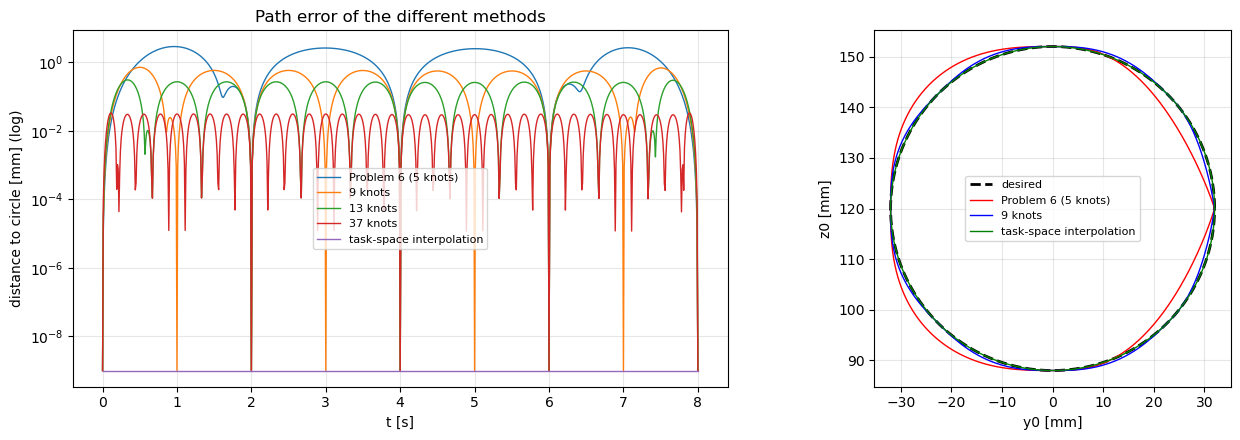

In [26]:
# comparing all the methods

paths = {"Problem 6 (5 knots)": P_actual}
for N in (9, 13, 37):
    paths[f"{N} knots"] = np.array([fk(q)[:3, 3] for q in more_knots(N)])
paths["task-space interpolation"] = np.array([fk(q)[:3, 3] for q in q_task])

print(f"{'method':28s} {'max error [mm]':>15s} {'RMS [mm]':>10s}")
errors = {}
for name, P in paths.items():
    errors[name] = circle_error(P)
    print(f"{name:28s} {errors[name].max():15.4f} {np.sqrt(np.mean(errors[name]**2)):10.4f}")

fig, axs = plt.subplots(1, 2, figsize=(14, 4.5))
for name, e in errors.items():
    axs[0].semilogy(t, np.maximum(e, 1e-9), label=name, lw=1)
axs[0].set_xlabel("t [s]"); axs[0].set_ylabel("distance to circle [mm] (log)")
axs[0].set_title("Path error of the different methods"); axs[0].legend(fontsize=8); axs[0].grid(alpha=0.3)

axs[1].plot(P_circle[:, 1], P_circle[:, 2], "k--", lw=2, label="desired")
for name, col in [("Problem 6 (5 knots)", "r"), ("9 knots", "b"), ("task-space interpolation", "g")]:
    axs[1].plot(paths[name][:, 1], paths[name][:, 2], col, lw=1, label=name)
axs[1].set_aspect("equal"); axs[1].set_xlabel("y0 [mm]"); axs[1].set_ylabel("z0 [mm]")
axs[1].legend(fontsize=8); axs[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

# Problem 8

In [27]:
# condition number along the path

def cond_J(q):
    return np.linalg.cond(J_stylus(q))        # ratio of largest to smallest singular value

# (a) along the exact circle from Problem 3: the 37 configurations + a dense version for a smooth curve
phi_dense = np.linspace(0, 2*np.pi, 361)
Q_dense = np.array([inverse_kinematics(circle(f), 0.0) for f in phi_dense])
cond_circle = np.array([cond_J(q) for q in Q_dense])
cond_37 = np.array([cond_J(q) for q in Q])

# (b) along the interpolated trajectory of Problem 6, and the task-space trajectory of Problem 7
cond_traj6 = np.array([cond_J(q) for q in q_t])
cond_task = np.array([cond_J(q) for q in q_task])

print(f"Exact circle (Problem 3):    cond(J) from {cond_circle.min():.1f} to {cond_circle.max():.1f}")
print(f"Problem 6 trajectory:        cond(J) from {cond_traj6.min():.1f} to {cond_traj6.max():.1f}")
print(f"Task-space traj. (Prob. 7):  cond(J) from {cond_task.min():.1f} to {cond_task.max():.1f}")

Exact circle (Problem 3):    cond(J) from 325.3 to 378.0
Problem 6 trajectory:        cond(J) from 325.3 to 378.0
Task-space traj. (Prob. 7):  cond(J) from 325.3 to 378.0


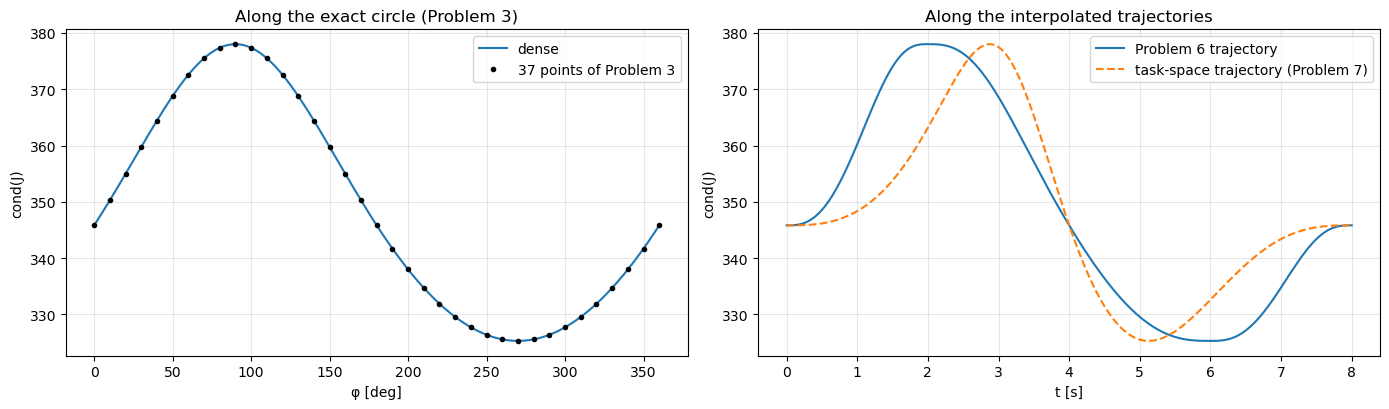

In [28]:
# plot the condition number

fig, axs = plt.subplots(1, 2, figsize=(14, 4.2))
axs[0].plot(np.degrees(phi_dense), cond_circle, label="dense")
axs[0].plot(np.degrees(np.linspace(0, 2*np.pi, 37)), cond_37, "ko", ms=3, label="37 points of Problem 3")
axs[0].set_xlabel("φ [deg]"); axs[0].set_ylabel("cond(J)")
axs[0].set_title("Along the exact circle (Problem 3)"); axs[0].legend()

axs[1].plot(t, cond_traj6, label="Problem 6 trajectory")
axs[1].plot(t, cond_task, "--", label="task-space trajectory (Problem 7)")
axs[1].set_xlabel("t [s]"); axs[1].set_ylabel("cond(J)")
axs[1].set_title("Along the interpolated trajectories"); axs[1].legend()
for ax in axs: ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

In [29]:
# where the singularities are (rank(A) < 4 <-> det A = 0)

# A = [J_v ; x4dot_z row] is the square 4x4 matrix we invert in Problems 5-7
x4_sym = T04[:3, 0]
S_x4 = sp.Matrix([[0, -x4_sym[2], x4_sym[1]],
                  [x4_sym[2], 0, -x4_sym[0]],
                  [-x4_sym[1], x4_sym[0], 0]])
row_sym = sp.simplify((-S_x4 * J4[3:, :])[2, :])           # x4dot_z row (Annex A)
A_sym = J4[:3, :].col_join(row_sym)
det_A = sp.factor(sp.simplify(A_sym.det()))
print("det A(q) ="); display(det_A)

# numerical value of det(A) along the circle
det_circle = np.array([np.linalg.det(task_matrix(q)) for q in Q_dense])
print(f"det(A) along the circle: from {det_circle.min():.3g} to {det_circle.max():.3g} mm^3   (singular = 0)")

# the factors of det(A) along the circle
r_tip = np.array([np.hypot(fk(q)[0, 3], fk(q)[1, 3]) for q in Q_dense])     # horizontal distance tip - base axis
print(f"theta3 along the circle:  {np.degrees(Q_dense[:, 2]).min():.1f} to {np.degrees(Q_dense[:, 2]).max():.1f} deg   (singular at 0 or ±180)")
print(f"horizontal reach r:       {r_tip.min():.1f} to {r_tip.max():.1f} mm   (singular at 0)")

det A(q) =


-8649*(93*sin(theta2) + 93*sin(theta2 + theta3) + 50*sin(theta2 + theta3 + theta4))*sin(theta3)*sin(theta2 + theta3 + theta4)

det(A) along the circle: from 1.22e+06 to 1.32e+06 mm^3   (singular = 0)
theta3 along the circle:  -109.8 to -79.7 deg   (singular at 0 or ±180)
horizontal reach r:       150.0 to 153.4 mm   (singular at 0)


# Problem 9

In [30]:
# torques along the cirlce

W = 1.0                                          # weight [N]
F = np.array([0, 0, -W, 0, 0, 0])                # force/torque applied to the end-effector: 1 N along -z0, no moment

def static_torque(q):
    J = J_stylus(q).copy()
    J[:3] /= 1000                                # mm -> m, so that tau comes out in N*m
    return J.T @ F

phi_dense = np.linspace(0, 2*np.pi, 361)
Q_dense = np.array([inverse_kinematics(circle(f), 0.0) for f in phi_dense])
tau = np.array([static_torque(q) for q in Q_dense])

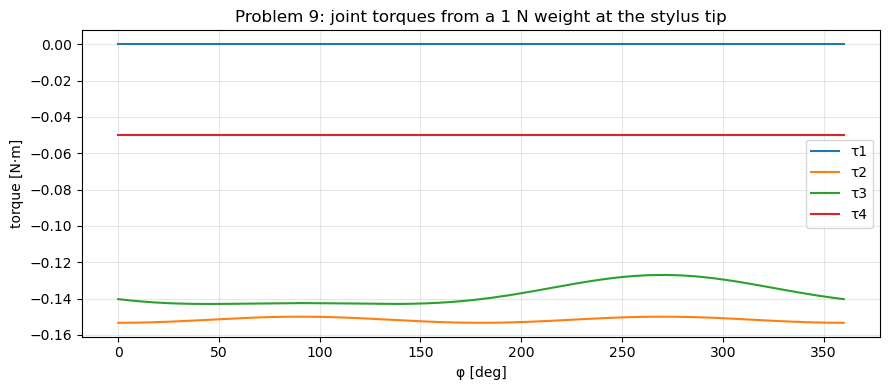

In [31]:
# plot

plt.figure(figsize=(9, 4))
for i in range(4):
    plt.plot(np.degrees(phi_dense), tau[:, i], label=f"τ{i+1}")
plt.xlabel("φ [deg]"); plt.ylabel("torque [N·m]"); plt.grid(alpha=0.3); plt.legend()
plt.title("Problem 9: joint torques from a 1 N weight at the stylus tip")
plt.tight_layout(); plt.show()

In [32]:
# values at four points, plus a check against the closed form

for phi, name in zip([0, np.pi/2, np.pi, 3*np.pi/2], ["0", "pi/2", "pi", "3pi/2"]):
    q = inverse_kinematics(circle(phi), 0.0)
    print(f"phi = {name:5s}  tau = {static_torque(q).round(4)} N*m")

# closed form: tau2 = -W * r  (r = horizontal distance from the base axis to the tip)
r_tip = np.array([np.hypot(fk(q)[0, 3], fk(q)[1, 3]) for q in Q_dense]) / 1000
print("max |tau2 - (-W r)| =", np.abs(tau[:, 1] + W * r_tip).max())

phi = 0      tau = [ 0.     -0.1534 -0.1403 -0.05  ] N*m
phi = pi/2   tau = [ 0.     -0.15   -0.1425 -0.05  ] N*m
phi = pi     tau = [ 0.     -0.1534 -0.1403 -0.05  ] N*m
phi = 3pi/2  tau = [ 0.    -0.15  -0.127 -0.05 ] N*m
max |tau2 - (-W r)| = 8.326672684688674e-17


# Problem 10

In [33]:
# estimate I0

# Link 1 ~ AX-12A servo housing: m = 60 g, box of about 32 x 50 x 40 mm (w x h x d)
m1_est = 0.060
w, h, d = 0.032, 0.050, 0.040          # [m]: w along x1, h along y1 (vertical), d along z1
Ixx = m1_est / 12 * (h**2 + d**2)
Iyy = m1_est / 12 * (w**2 + d**2)
Izz = m1_est / 12 * (w**2 + h**2)
print(f"Box estimate: Ixx = {Ixx:.2e}, Iyy = {Iyy:.2e}, Izz = {Izz:.2e} kg m^2")
I0_value = 2e-5                         # chosen I0 (rounded, same order as Ixx)
print(f"Chosen I0 = {I0_value:.1e} kg m^2")

Box estimate: Ixx = 2.05e-05, Iyy = 1.31e-05, Izz = 1.76e-05 kg m^2
Chosen I0 = 2.0e-05 kg m^2


In [34]:
# model in SI units (transforms, centres of mass, intertia tensors)

R_ = sp.Rational
I0 = sp.Symbol('I_0', positive=True)
g0 = R_(981, 100)                       # 9.81 m/s^2

# DH in metres (same table as before, with the +90 deg offset on theta2)
A1 = dh_transformation(theta1, R_(50, 1000), 0, sp.pi/2)
A2 = dh_transformation(theta2 + sp.pi/2, 0, R_(93, 1000), 0)
A3 = dh_transformation(theta3, 0, R_(93, 1000), 0)
A4 = dh_transformation(theta4, 0, R_(50, 1000), 0)
Tm = [sp.eye(4), A1, A1*A2, A1*A2*A3, A1*A2*A3*A4]          # T_0^0 ... T_4^0

masses = [R_(60, 1000), R_(80, 1000), R_(80, 1000), R_(40, 1000)]   # [kg]

# Centre of mass of link i in its own frame {i} (Figure 2), homogeneous coordinates [m]
r_c_local = [sp.Matrix([0, -R_(20, 1000), 0, 1]),            # CM1: 20 mm below {1}  (-y1)
             sp.Matrix([-R_(30, 1000), 0, 0, 1]),            # CM2: 30 mm before {2} (-x2)
             sp.Matrix([-R_(30, 1000), 0, 0, 1]),            # CM3: 30 mm before {3} (-x3)
             sp.Matrix([-R_(25, 1000), R_(15, 1000), 0, 1])] # CM4: 25 mm below, 15 mm left of {4}

# Inertia tensors about the CM, axes parallel to frame {i}
I_local = [I0 * sp.diag(1, R_(4, 10), R_(9, 10)),
           I0 * sp.diag(R_(45, 100), R_(14, 10), R_(12, 10)),
           I0 * sp.diag(R_(45, 100), R_(14, 10), R_(12, 10)),
           I0 * sp.diag(R_(1, 2), R_(1, 2), R_(1, 2))]

In [35]:
# intertia matrix D(q), potential energy and gravity vector g(q)

#   D = sum_i  m_i Jv_ci^T Jv_ci + Jw_i^T R_i I_i R_i^T Jw_i
#   P = sum_i  m_i g0 z_ci
q_vec = sp.Matrix([theta1, theta2, theta3, theta4])
D = sp.zeros(4, 4)
P = 0
for i in range(4):
    r_ci = (Tm[i+1] * r_c_local[i])[:3, :]                   # CM position in the base frame
    Jv_ci = sp.zeros(3, 4)
    Jw_i = sp.zeros(3, 4)
    for j in range(i + 1):                                   # only joints 1..i move link i
        z = Tm[j][:3, 2]
        o = Tm[j][:3, 3]
        Jv_ci[:, j] = z.cross(r_ci - o)                      # z_{j-1} x (r_ci - o_{j-1})
        Jw_i[:, j] = z                                       # z_{j-1}
    R_i = Tm[i+1][:3, :3]
    D += masses[i] * Jv_ci.T * Jv_ci + Jw_i.T * R_i * I_local[i] * R_i.T * Jw_i
    P += masses[i] * g0 * r_ci[2]

D = D.applyfunc(sp.simplify)                                 # takes ~20-30 s
g_vec = sp.Matrix([sp.simplify(sp.diff(P, qk)) for qk in q_vec])   # g_k = dP/dq_k
print("g(q) ="); display(sp.N(g_vec, 4))
print("d11 ="); display(sp.N(D[0, 0], 4))
print("d22 ="); display(sp.N(D[1, 1], 4))

g(q) =


Matrix([
[                                                                                                                                  0],
[-0.1589*sin(theta2) - 0.08594*sin(theta2 + theta3) - 0.00981*sin(theta2 + theta3 + theta4) - 0.005886*cos(theta2 + theta3 + theta4)],
[                     -0.08594*sin(theta2 + theta3) - 0.00981*sin(theta2 + theta3 + theta4) - 0.005886*cos(theta2 + theta3 + theta4)],
[                                                    -0.00981*sin(theta2 + theta3 + theta4) - 0.005886*cos(theta2 + theta3 + theta4)]])

d11 =


-0.475*I_0*cos(2*theta2) - 0.475*I_0*cos(2*theta2 + 2*theta3) + 2.75*I_0 - 5.58e-5*sin(theta4) - 5.58e-5*sin(theta3 + theta4) + 5.58e-5*sin(2*theta2 + theta3 + theta4) + 5.58e-5*sin(2*theta2 + 2*theta3 + theta4) + 1.5e-5*sin(2*theta2 + 2*theta3 + 2*theta4) - 0.0006777*cos(2*theta2) + 0.0008147*cos(theta3) + 9.3e-5*cos(theta4) - 0.0008147*cos(2*theta2 + theta3) - 0.0003317*cos(2*theta2 + 2*theta3) + 9.3e-5*cos(theta3 + theta4) - 9.3e-5*cos(2*theta2 + theta3 + theta4) - 9.3e-5*cos(2*theta2 + 2*theta3 + theta4) - 8.0e-6*cos(2*theta2 + 2*theta3 + 2*theta4) + 0.001026

d22 =


2.9*I_0 - 0.0001116*sin(theta4) - 0.0001116*sin(theta3 + theta4) + 0.001629*cos(theta3) + 0.000186*cos(theta4) + 0.000186*cos(theta3 + theta4) + 0.002053

In [36]:
# Coriolis/centrifugal matrix from the Christoffel symbols, plus numeric functions

#   c_ijk = 1/2 (d d_kj/d q_i + d d_ki/d q_j - d d_ij/d q_k),   C_kj = sum_i c_ijk qdot_i
qd_sym = sp.symbols('qd1:5', real=True)
C = sp.zeros(4, 4)
for k in range(4):
    for j in range(4):
        C[k, j] = sum(R_(1, 2) * (sp.diff(D[k, j], q_vec[i]) + sp.diff(D[k, i], q_vec[j])
                                  - sp.diff(D[i, j], q_vec[k])) * qd_sym[i] for i in range(4))

D_func = sp.lambdify((q_vec, I0), D, 'numpy')
C_func = sp.lambdify((q_vec, qd_sym, I0), C, 'numpy')
g_func = sp.lambdify((q_vec,), g_vec, 'numpy')

def dynamics_torque(q, qd, qdd, I0_val=I0_value):
    Dn = np.array(D_func(q, I0_val), float)
    Cn = np.array(C_func(q, qd, I0_val), float)
    gn = np.array(g_func(q), float).ravel()
    return Dn @ qdd + Cn @ qd + gn, Dn @ qdd, Cn @ qd, gn     # total, inertial, Coriolis, gravity

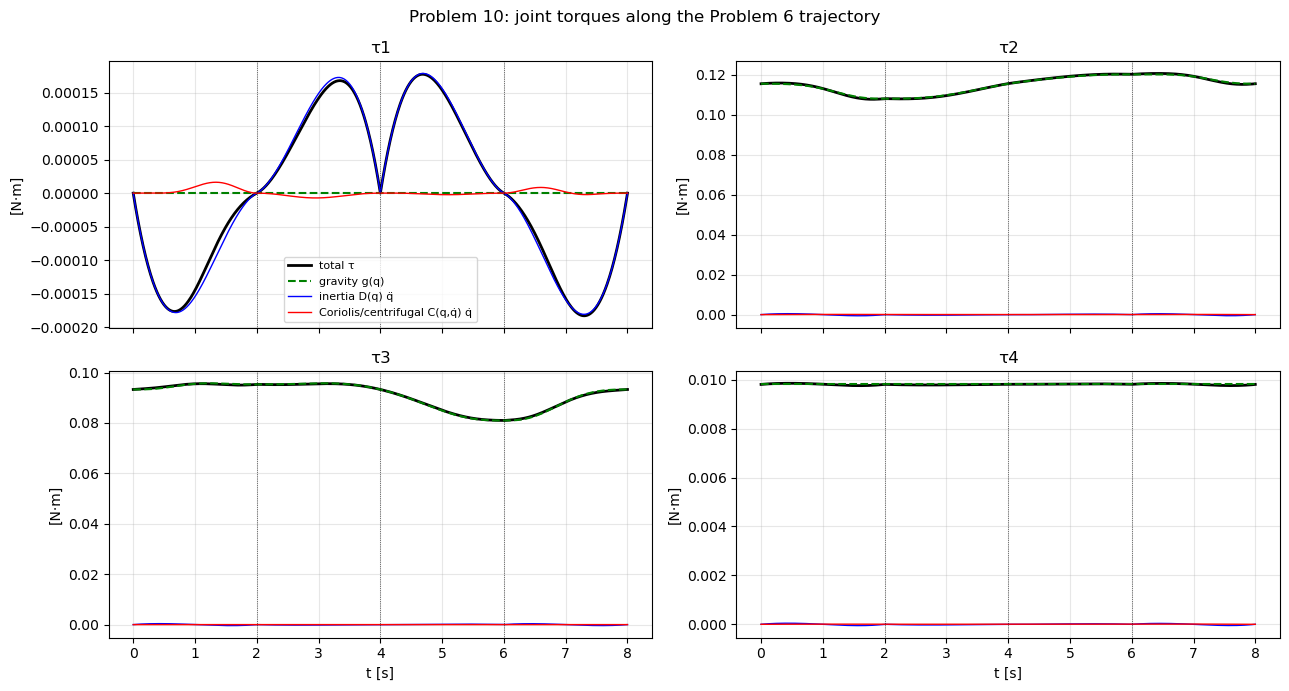

max |total|     [N m]: [0.00018 0.12071 0.09559 0.00986]
max |inertia|   [N m]: [0.000181 0.000586 0.000402 0.000053]
max |Coriolis|  [N m]: [0.000016 0.000102 0.000013 0.00001 ]
max |gravity|   [N m]: [0.      0.12025 0.09575 0.00981]


In [37]:
# joint torques along the Problem 6 trajectory

out = [dynamics_torque(q, qd, qdd) for q, qd, qdd in zip(q_t, qd_t, qdd_t)]
tau_tot = np.array([o[0] for o in out]); tau_D = np.array([o[1] for o in out])
tau_C = np.array([o[2] for o in out]);   tau_g = np.array([o[3] for o in out])

fig, axs = plt.subplots(2, 2, figsize=(13, 7), sharex=True)
for i, ax in enumerate(axs.ravel()):
    ax.plot(t, tau_tot[:, i], "k", lw=2, label="total τ")
    ax.plot(t, tau_g[:, i], "g--", label="gravity g(q)")
    ax.plot(t, tau_D[:, i], "b", lw=1, label="inertia D(q) q̈")
    ax.plot(t, tau_C[:, i], "r", lw=1, label="Coriolis/centrifugal C(q,q̇) q̇")
    ax.set_title(f"τ{i+1}"); ax.set_ylabel("[N·m]"); ax.grid(alpha=0.3)
    for tk in [2, 4, 6]: ax.axvline(tk, color="k", lw=0.5, ls=":")
axs[1, 0].set_xlabel("t [s]"); axs[1, 1].set_xlabel("t [s]"); axs[0, 0].legend(fontsize=8)
fig.suptitle("Problem 10: joint torques along the Problem 6 trajectory")
plt.tight_layout(); plt.show()

print("max |total|     [N m]:", np.abs(tau_tot).max(0).round(5))
print("max |inertia|   [N m]:", np.abs(tau_D).max(0).round(6))
print("max |Coriolis|  [N m]:", np.abs(tau_C).max(0).round(7))
print("max |gravity|   [N m]:", np.abs(tau_g).max(0).round(5))